In [1]:
#一键检验稳定性
import time
import json
import requests
import pandas as pd
import numpy as np
import requests
from requests.auth import HTTPBasicAuth
from urllib.request import urlopen


alpha_id_ori='vRN2njMb'


def locate_alpha(s, alpha_id):
    while True:
        alpha = s.get("https://api.worldquantbrain.com/alphas/" + alpha_id)
        if "retry-after" in alpha.headers:
            time.sleep(float(alpha.headers["Retry-After"]))
        else:
            break
    string = alpha.content.decode('utf-8')
    metrics = json.loads(string)
    #print(metrics["regular"]["code"])
    
    dateCreated = metrics["dateCreated"]
    sharpe = metrics["is"]["sharpe"]
    fitness = metrics["is"]["fitness"]
    turnover = metrics["is"]["turnover"]
    margin = metrics["is"]["margin"]
    decay = metrics["settings"]["decay"]
    exp = metrics['regular']['code']
    universe=metrics["settings"]["universe"]
    truncation=metrics["settings"]["truncation"]
    neutralization=metrics["settings"]["neutralization"]
    region=metrics["settings"]["region"]
    
    # triple =pd.DataFrame([[alpha_id,  sharpe, turnover, fitness, margin]])
    triple =[alpha_id,  sharpe, turnover, fitness, margin, exp,region,universe,neutralization,decay,truncation]
    return triple


def login():
    import logging
    import os
    from pathlib import Path
    import urllib3
    import yaml

    urllib3.disable_warnings(urllib3.exceptions.InsecureRequestWarning)

    def resolve_config_path():
        if os.environ.get("WQB_CONFIG"):
            configured = Path(os.environ["WQB_CONFIG"]).expanduser()
            if configured.is_file():
                return configured

        current_dir = Path.cwd().resolve()
        for level in range(4):
            config_path = current_dir / "Password" / "config.yaml"
            if config_path.is_file():
                return config_path
            current_dir = current_dir.parent
        raise FileNotFoundError("未找到凭据文件；请设置 WQB_CONFIG，或把配置放在仓库 Password/config.yaml。")

    try:
        with resolve_config_path().open("r", encoding="utf-8") as file:
            config = yaml.safe_load(file)
        if not isinstance(config, dict) or not config.get("username") or not config.get("password"):
            raise ValueError("配置必须包含非空 username 和 password")
        base_url = str(config.get("api_base_url", "https://api.worldquantbrain.com")).rstrip("/")
        s = requests.Session()
        s.auth = (config["username"], config["password"])
        response = s.post(f"{base_url}/authentication", timeout=30, verify=False)
        response.raise_for_status()
        return s
    except Exception as exc:
        logging.error("获取 Session 失败：%s", exc)
        return None

s = login()
sharp_list = []
df=pd.DataFrame(columns=['alpha_id','sharpe','turnover','fitness','margin'])




alpha_line = []
tem=locate_alpha(s, alpha_id_ori)

[alpha_id,  sharpe, turnover, fitness, margin, exp,region,universe,neutralization,decay,truncation]=tem



# 根据 decay 的值选择不同的 decay_tem 列表
decay_tem_list = [0,1,5,20]

# 固定的 neutralization_tem 列表
neutralization_tem_list =[
         "STATISTICAL",
         "CROWDING",
         "FAST",
        "SLOW",
        "MARKET",
        "SECTOR",
        "INDUSTRY",
        "SUBINDUSTRY",
        "COUNTRY"
    ]
# neutralization_tem_list = ['SUBINDUSTRY']
# 使用列表推导式生成 simulation_data
alpha_line.extend(
    {
        'type': 'REGULAR',
        'settings': {
            'instrumentType': 'EQUITY',
            'region': region,
            'universe': universe,
            'delay': 1,
            'decay': decay_tem,
            'neutralization': neutralization_tem,
            'truncation': truncation,
            'pasteurization': 'ON',
            'unitHandling': 'VERIFY',
            'nanHandling': 'ON',
            'language': 'FASTEXPR',
            'visualization': False,
            'testPeriod': "P0Y",
            'maxTrade': 'OFF'
        },
        'regular': exp
    }
    for decay_tem in decay_tem_list
    for neutralization_tem in neutralization_tem_list
)



            
            
print(len(alpha_line))
wbs=[]
for alpha_data in alpha_line:
    while True:
        count = 0
        try:
            # Send multisimulation request
            response = s.post('https://api.worldquantbrain.com/simulations', json=alpha_data)
            # Check response
            
            if len(response.headers["Location"]) >0:
                print(f"Alpha location get successfully: {response.headers['Location']}")
                wbs.append(response.headers['Location'])
                break
        except:
            count = count+1
            #s = sign_in(username, password)
            print("Error in sending simulation request. And retry after 5s")
            time.sleep(5)
            if count>10:
                s = login()
            if count>30:
                break
print(len(wbs))

36
Alpha location get successfully: https://api.worldquantbrain.com/simulations/MukbMaBH58Xcx31erStLPb7
Alpha location get successfully: https://api.worldquantbrain.com/simulations/1MOPyL25e582cwLwvGCbcKc
Alpha location get successfully: https://api.worldquantbrain.com/simulations/24PCFC4zW4Ka8Y6w3IWmbaS
Alpha location get successfully: https://api.worldquantbrain.com/simulations/3aMtwxmq4DFa6pFBGfvHzC
Error in sending simulation request. And retry after 5s
Error in sending simulation request. And retry after 5s
Error in sending simulation request. And retry after 5s
Error in sending simulation request. And retry after 5s
Error in sending simulation request. And retry after 5s
Error in sending simulation request. And retry after 5s
Error in sending simulation request. And retry after 5s
Error in sending simulation request. And retry after 5s
Error in sending simulation request. And retry after 5s
Error in sending simulation request. And retry after 5s
Error in sending simulation reques

KeyboardInterrupt: 

In [ ]:
import time
df_list=[]
df_list=pd.DataFrame(columns=['alpha_id','neutralization','decay','sharpe','fitness','turnover','margin'])
tem=locate_alpha(s, alpha_id_ori)
[alpha_id_ori,  sharpe, turnover, fitness, margin, exp,region,universe,neutralization,decay,truncation]=tem
new_row=[alpha_id_ori,neutralization,decay,sharpe,fitness,turnover,margin]
df_list.loc[len(df_list)]=new_row
print(df_list)
df_list

for wb in wbs:
    sess = login()

    # 发送请求
    url = wb

    while 1:  #对1个simulated测试
        data = sess.get(url).text
        #sleep(5)
        try:
            if 'progress' not in data and 'error' not in data:
                time.sleep(5)
                json_data = json.loads(data)  # 将文本转为字典
                alpha_value = json_data["alpha"]  # 直接获取 alpha 字段
                print(alpha_value)
                tem=locate_alpha(s, alpha_value)
                [alpha_id,  sharpe, turnover, fitness, margin, exp,region,universe,neutralization,decay,truncation]=tem
                new_row=[alpha_id,neutralization,decay,sharpe,fitness,turnover,margin]
                df_list.loc[len(df_list)] = new_row  # 直接赋值（确保 df 已初始化列名）
                break
            else :
                print("progressing")
                #time.sleep(60)
                continue
        except:
                print("progressing")
                #time.sleep(60)
                continue            
df_list= df_list.drop_duplicates(subset="alpha_id", keep="first")
df_list

  alpha_id neutralization  decay  sharpe  fitness  turnover    margin
0  zr5RZeV       INDUSTRY      3     2.3     1.87    0.1077  0.001538
0xMen2p
vZveeNG
vZvem9a
dYREYNj
Jovn0Wm
oRg3Yan
oRg3b8v
QO929JX
dYRE3GY
progressing


In [ ]:
from machine_lib import * 
import machine_lib
s = login()
def locate_alpha(s, alpha_id):
    while True:
        alpha = s.get("https://api.worldquantbrain.com/alphas/" + alpha_id)
        if "retry-after" in alpha.headers:
            time.sleep(float(alpha.headers["Retry-After"]))
        else:
            break
    string = alpha.content.decode('utf-8')
    metrics = json.loads(string)
    #print(metrics["regular"]["code"])
    
    #dateCreated = metrics["dateCreated"]
    sharpe = metrics["is"]["sharpe"]
    fitness = metrics["is"]["fitness"]
    turnover = metrics["is"]["turnover"]
    margin = metrics["is"]["margin"]
    decay = metrics["settings"]["decay"]
    exp = metrics['regular']['code']
    region=metrics["settings"]["region"]
    triple = [ alpha_id, exp, sharpe, turnover, fitness, margin,  decay,region]
    return triple
A=[]
for i in a:
    try:
        print(locate_alpha(s,i))
        A.append(locate_alpha(s,i))
    except:
        print('error',i)
A=pd.DataFrame(A)
A

In [ ]:
from time import sleep
def get_pnl(s, alpha_id):
    finished = False
    while True:
        pnl = s.get('https://api.worldquantbrain.com/alphas/' + alpha_id + '/recordsets/pnl')
        if pnl.headers.get('Retry-After', 0) == 0:
             break
        # print('Sleeping for ' + pnl.headers['Retry-After'] + ' seconds')
        sleep(float(pnl.headers['Retry-After']))
    # print('PNL retrieved')
    return pnl
s 
df1 = pd.DataFrame()

for alpha_id in df_list['alpha_id'].unique():
    print(alpha_id)
    json_data = get_pnl(s, alpha_id).json()['records']
    df = pd.DataFrame(json_data)
    df=df.iloc[:,0:2]
    df.columns = ['date', alpha_id]
    df.set_index('date', inplace=True)
    df1 = pd.merge(df1, df, left_index=True, right_index=True, how='outer')
    sleep(5)

df1.index = pd.to_datetime(df1.index)
start_time=df1.index[0]-pd.Timedelta(days=1)
start_time

df1

98J0JgV
px86rP6
ORopaVJ
8Vnzaq7
zgO9wME
w3LR17Q
qOgAPmE
bJvLNJm


,98J0JgV,px86rP6,ORopaVJ,8Vnzaq7,zgO9wME,w3LR17Q,qOgAPmE,bJvLNJm
date,,,,,,,,
2013-01-21,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2013-01-22,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2013-01-23,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2013-01-24,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2013-01-25,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...
2023-01-16,7858951.0,23928197.0,14125506.0,13228388.0,7858951.0,0.0,13283095.0,23928197.0
2023-01-17,7866200.0,24148374.0,14215629.0,13290652.0,7866200.0,0.0,13340553.0,24148374.0
2023-01-18,7896752.0,23935528.0,14248251.0,13325570.0,7896752.0,0.0,13351388.0,23935528.0


98J0JgV


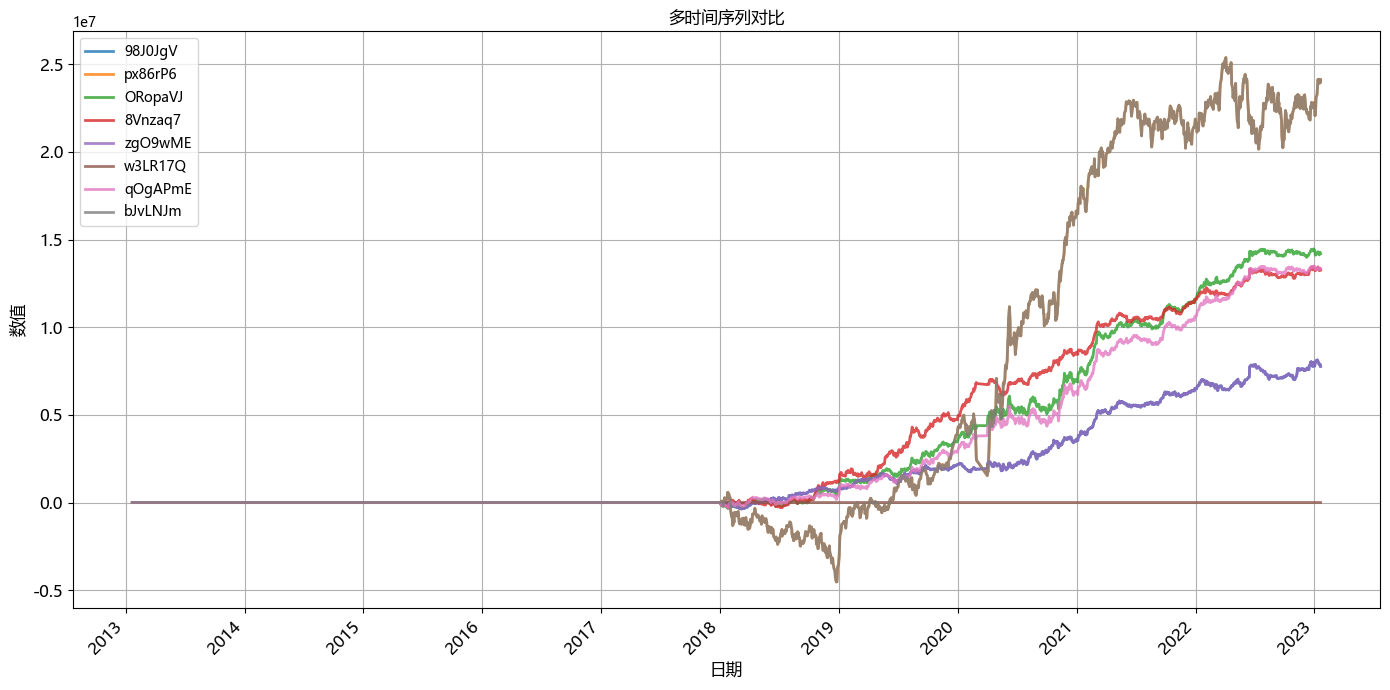

alpha_id  sharpe  fitness  turnover    margin
neutralization decay                                              
COUNTRY        0      qOgAPmE    1.94     2.79    0.0207  0.025084
INDUSTRY       0      98J0JgV    1.62     1.78    0.0259  0.011657
               0      zgO9wME    1.62     1.78    0.0259  0.011657
MARKET         0      ORopaVJ    2.03     3.02    0.0192  0.028817
NONE           0      px86rP6    1.09     2.11    0.0141  0.066690
               1      bJvLNJm    1.09     2.11    0.0141  0.066690
SECTOR         0      8Vnzaq7    2.36     3.39    0.0238  0.021625
SUBINDUSTRY    0      w3LR17Q    0.00      NaN    0.0000  0.000000

In [ ]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']  # 使用微软雅黑
plt.rcParams['axes.unicode_minus'] = False  # 解决负号显示问题
import matplotlib.pyplot as plt

# 绘制所有列（自动分配颜色和标签）
ax = df1.plot(
    figsize=(14, 7),
    linewidth=2,
    title='多时间序列对比',
    grid=True,
    alpha=0.8,
    fontsize=12
)

# 添加图例和标签
ax.set_xlabel('日期', fontsize=12)
ax.set_ylabel('数值', fontsize=12)
ax.legend(loc='upper left', frameon=True)
print(alpha_id_ori)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
df_sorted = df_list.sort_values("neutralization")
df_multiindex = df_sorted.set_index(["neutralization", "decay"])
df_multiindex